## ETTh2 Transformer Temperature Tracker

### ETTH2 dataset

#### Initial Preview

In [1]:
# Initial setup required for loading the CSV file and plotting the data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Load the CSV from the same folder as this notebook.
df = pd.read_csv("ETTh2.csv", parse_dates=["date"])

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()

Loaded 17,420 rows and 8 columns.


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001
2,2016-07-01 02:00:00,37.946999,11.309,35.330002,9.007,2.100,0.000,36.465000
3,2016-07-01 03:00:00,38.952000,11.895,35.543999,9.436,3.380,1.215,33.608501
4,2016-07-01 04:00:00,38.113998,11.476,35.410000,9.623,2.036,0.000,31.850500


The table below explains the acronyms used inside the dataset:

| **HUFL** | **HULL** | **MUFL** | **MULL** | **LUFL** | **LULL** | **OT** |
|----------|----------|----------|----------|----------|----------|--------|
| High Useful Load | High Useless Load | Middle Useful Load | Middle Useless Load | Low Useful Load | Low Useless Load | Oil Temperature |

**Prediction target:** `OT` represents the transformer's oil temperature, which we aim to predict using the changing load measurements.

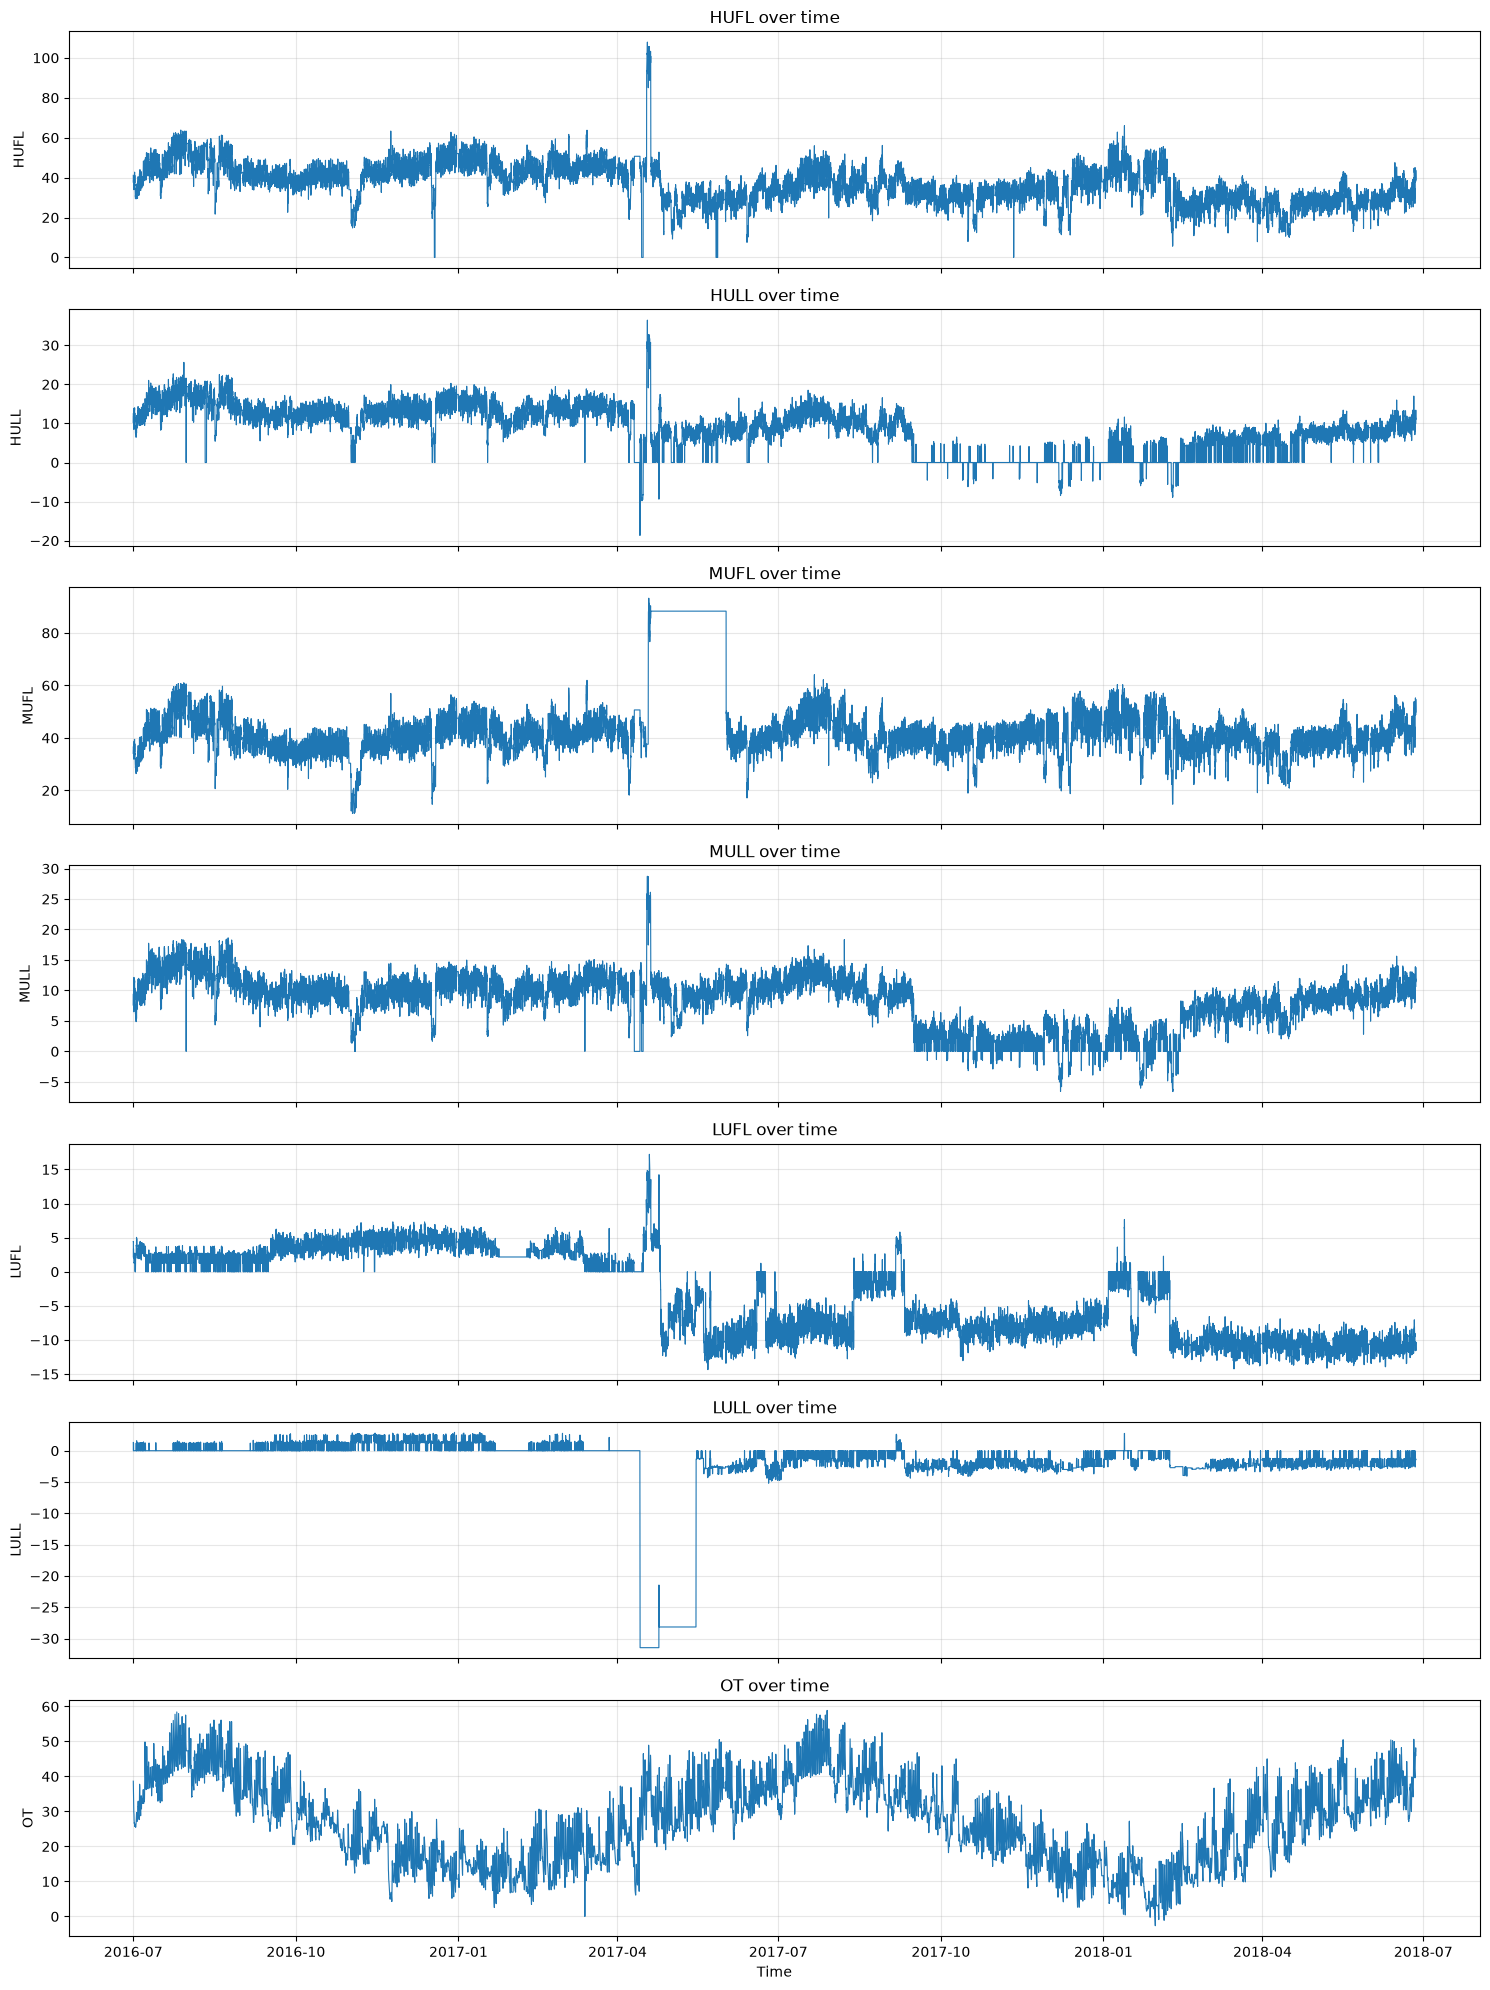

In [3]:
# plot all variables over time

variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]

fig, axes = plt.subplots(7, 1, figsize=(15, 20), sharex=True)

for ax, variable in zip(axes, variables):
    ax.plot(df["date"], df[variable], linewidth=0.8)
    ax.set_title(f"{variable} over time")
    ax.set_ylabel(variable)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
plt.tight_layout()
plt.show()

#### Preprocessing and Data Split

In [5]:
data = df.copy()

# Validate timestamps and put observations in chronological order.
data["date"] = pd.to_datetime(data["date"], errors="coerce")

if data["date"].isna().any():
    raise ValueError("Missing or invalid timestamps must be corrected first.")

data = data.sort_values("date").reset_index(drop=True)

# Convert measurements to numbers; treat invalid/infinite values as missing.
variables = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]
data[variables] = (
    data[variables]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

# Report missing values and drop any affected measurement columns.
missing_counts = data[variables].isna().sum()
print("Missing values per column:")
print(missing_counts)

columns_to_drop = missing_counts[missing_counts > 0].index.tolist()
data = data.drop(columns=columns_to_drop)
print("\nDropped columns:", columns_to_drop or "None")

if "OT" in columns_to_drop:
    print("WARNING: OT was dropped; it is needed for temperature prediction.")


Missing values per column:
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

Dropped columns: None


In [ ]:
# Using the 60/20/20 split for training, validation, and testing.
# This was defined inside the project description requirements. 



### Stage 1 - Baseline Models


### Stage 2 - Advanced Models


### Stage 3 - Transformer Architecture Implementation


### Jetson Deployment